<a href="https://colab.research.google.com/github/Xyrfo/Pembelajaran-Mesin/blob/main/JS11/Lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 1 - Klasifikasi Cats vs. Dogs dengan CNN

## Deskripsi
Pada praktikum ini kita membangun model **Convolutional Neural Network (CNN)** sederhana untuk membedakan citra **kucing** dan **anjing**. CNN mempelajari fitur citra secara otomatis melalui layer konvolusi, sehingga tidak perlu ekstraksi fitur manual.

## Tujuan
1. Menyiapkan dataset citra dengan `ImageDataGenerator`.
2. Membangun CNN dasar (konvolusi, pooling, flatten, fully connected).
3. Melatih dan mengevaluasi model klasifikasi biner.
4. Melakukan prediksi pada satu citra.


In [1]:
import tensorflow as tf

print('TensorFlow:', tf.__version__)
print('GPU tersedia:', len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow: 2.21.0
GPU tersedia: False


## Menyiapkan Dataset

Struktur folder yang diharapkan:

```
dataset/
  training_set/
    cats/
    dogs/
  test_set/
    cats/
    dogs/
  single_prediction/
    cat_or_dog_1.jpg
```

In [2]:
import os
import zipfile
from google.colab import files

if not os.path.exists('dataset/training_set'):
    uploaded = files.upload()  # pilih dataset.zip
    for name in uploaded:
        if name.lower().endswith('.zip'):
            with zipfile.ZipFile(name, 'r') as z:
                z.extractall('.')
    print('Ekstrak selesai. Pastikan struktur folder sesuai.')
else:
    print('Dataset sudah tersedia, upload dilewati.')

print('Isi dataset:', os.listdir('dataset') if os.path.exists('dataset') else 'belum ada')

Saving dataset.zip to dataset (1).zip
Ekstrak selesai. Pastikan struktur folder sesuai.
Isi dataset: ['.DS_Store', 'single_prediction', 'test_set', 'training_set']


## Langkah 1 - Import Library

`ImageDataGenerator` dipakai untuk membaca citra dari folder sekaligus melakukan augmentasi ringan.

In [3]:
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator

## Langkah 2.1 - Pra Pengolahan Data Training

Augmentasi membuat model lebih tahan terhadap variasi citra:
- `rescale=1./255`: normalisasi piksel ke rentang 0-1.
- `shear_range` dan `zoom_range`: koreksi kemiringan dan pembesaran.
- `horizontal_flip`: pencerminan horizontal.

In [4]:
train_datagen = ImageDataGenerator(rescale=1./255,
                                   shear_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True)

training_set = train_datagen.flow_from_directory('dataset/training_set',
                                                 target_size=(64, 64),
                                                 batch_size=32,
                                                 class_mode='binary')

Found 8000 images belonging to 2 classes.


## Langkah 2.2 - Pra Pengolahan Data Testing

Data testing hanya dinormalisasi, tanpa augmentasi, agar evaluasi mencerminkan data asli.

In [5]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_set = test_datagen.flow_from_directory('dataset/test_set',
                                            target_size=(64, 64),
                                            batch_size=32,
                                            class_mode='binary')

print('class_indices:', training_set.class_indices)

Found 2000 images belonging to 2 classes.
class_indices: {'cats': 0, 'dogs': 1}


## Langkah 3 - Pembuatan Model CNN

CNN terdiri dari **blok konvolusi** (ekstraksi fitur) dan **blok fully connected** (klasifikasi).

### Langkah 3.1 - Inisiasi Model CNN

In [6]:
cnn = tf.keras.models.Sequential()

### Langkah 3.2 - Layer Konvolusi 1

32 filter berukuran 3x3 dengan aktivasi ReLU. `input_shape=[64, 64, 3]` karena citra RGB 64x64.

In [7]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Langkah 3.3 - Layer Pooling 1

Max pooling 2x2 dengan stride 2 mengurangi ukuran feature map dan mempertahankan fitur terkuat.

In [8]:
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

### Langkah 3.4 - Layer Konvolusi 2 dan Pooling 2

In [9]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

### Langkah 3.5 - Flattening

Mengubah feature map 2D menjadi vektor 1D sebelum masuk ke fully connected layer.

In [10]:
cnn.add(tf.keras.layers.Flatten())

### Langkah 3.6 - Fully Connected Layer 1 (Input)

128 neuron dengan ReLU untuk mempelajari kombinasi fitur.

In [11]:
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

### Langkah 3.7 - Fully Connected Layer 2 (Output)

Satu neuron sigmoid menghasilkan probabilitas kelas positif.

In [12]:
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

### Langkah 3.8 - Compile Model CNN

`binary_crossentropy` dipakai karena klasifikasi hanya dua kelas (kucing vs anjing).

In [13]:
cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

## Langkah 4 - Fit CNN

Model dilatih 25 epoch. `validation_data=test_set` memantau performa pada data yang tidak dilatih.

In [14]:
history = cnn.fit(x=training_set, validation_data=test_set, epochs=25)

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 68s 265ms/step - accuracy: 0.5828 - loss: 0.6744 - val_accuracy: 0.6695 - val_loss: 0.6125
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 66s 263ms/step - accuracy: 0.6609 - loss: 0.6118 - val_accuracy: 0.6740 - val_loss: 0.6121
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 66s 262ms/step - accuracy: 0.6999 - loss: 0.5623 - val_accuracy: 0.7345 - val_loss: 0.5404
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 63s 253ms/step - accuracy: 0.7331 - loss: 0.5264 - val_accuracy: 0.7495 - val_loss: 0.5110
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 65s 258ms/step - accuracy: 0.7542 - loss: 0.5067 - val_accuracy: 0.7130 - val_loss: 0.5884
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 64s 256ms/step - accuracy: 0.7642 - loss: 0.4877 - val_accuracy: 0.7560 - val_loss: 0.4953
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 69s 275ms/step - accuracy: 0.7775 - loss: 0.4608 - val_accuracy: 0.7590 - val_loss: 0.5086
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 65s 258ms/step - accuracy: 0.7883 - loss: 0

## Visualisasi Proses Training

Grafik akurasi membantu melihat apakah model masih belajar atau mulai overfitting.

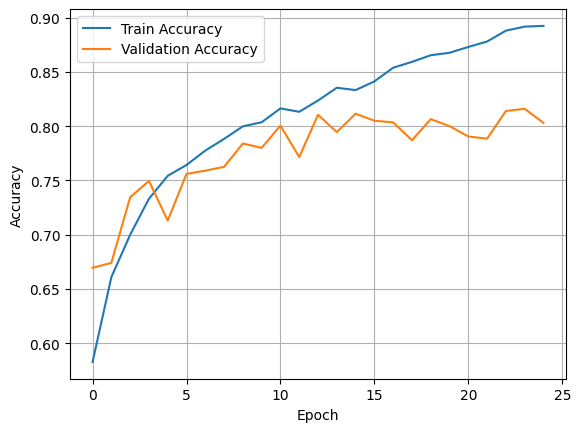

In [15]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

## Langkah 5 - Prediksi dengan 1 Citra

Gambar diubah ke array, ditambah dimensi batch, lalu diprediksi. Nilai `1` berarti anjing dan `0` berarti kucing, mengikuti `class_indices`.

In [16]:
import os

path = 'dataset/single_prediction/cat_or_dog_1.jpg'

if os.path.exists(path):
    test_image = tf.keras.utils.load_img(path, target_size=(64, 64))
    test_image = tf.keras.utils.img_to_array(test_image)
    test_image = np.expand_dims(test_image, axis=0)

    result = cnn.predict(test_image)
    prediction = 'dog' if result[0][0] == 1 else 'cat'

    print('class_indices:', training_set.class_indices)
    print('Skor prediksi:', result[0][0])
    print('Prediksi:', prediction)
else:
    print('File single_prediction belum tersedia. Prediksi dilewati.')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
class_indices: {'cats': 0, 'dogs': 1}
Skor prediksi: 1.0
Prediksi: dog


## Interpretasi

- **Akurasi training naik** menandakan model belajar pola citra.
- Jika **akurasi validasi tertinggal jauh**, model mulai overfitting; augmentasi dan penambahan data dapat membantu.
- **Sigmoid** mengeluarkan nilai 0-1, sehingga ambang 0.5 membagi kelas kucing dan anjing.
- `class_indices` menunjukkan urutan label yang dipelajari generator; pastikan interpretasi prediksi sesuai urutan tersebut.